# Chapter-13: Implementing Memory

# <font color="#800000">Implementing Memory In Agents</font>

## <font color="#3366FF">Implementing Short-Term Memory</font>

### Example Of Short-Term Memory

#### Setup

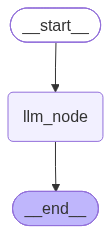

In [3]:
import os
from dotenv import load_dotenv
from langchain.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Define OpenAI Chat Model
llm = ChatOpenAI(model="gpt-5-mini") 

## Define System Message
system_msg = """You are a travel planner assistant. You should always give brief response in one line """

## Define llm node function
def llm_node(state: MessagesState):
    return {"messages": [llm.invoke([SystemMessage(content=system_msg)]+state["messages"])]}

## Create StateGraph
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("llm_node", llm_node)
graph_builder.add_edge(START, "llm_node")
graph_builder.add_edge("llm_node", END)

## Initialize Checkpointer
checkpointer = InMemorySaver()

## Compile graph
graph = graph_builder.compile(checkpointer=checkpointer)

## Visualize Graph (optional)
display(Image(graph.get_graph().draw_mermaid_png()))


#### Start First Session

In [4]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "session1"}}

## Invoke Graph
session1_response = graph.invoke({"messages": [HumanMessage(content="Suggest a destination for safari")]}, config=config)

## Print AI Message
session1_response["messages"][-1].pretty_print()


================================== Ai Message ==================================

Serengeti National Park, Tanzania — iconic for the Great Migration and abundant Big Five sightings; best visited June–October.


#### Start Second Session

In [5]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "session2"}}

## Invoke Graph
session2_response = graph.invoke({"messages": [HumanMessage(content="Tell me an option for beach holiday?")]}, config=config)

## Print AI Message
session2_response["messages"][-1].pretty_print()


================================== Ai Message ==================================

Bali (Seminyak/Canggu) — surf-friendly beaches, lively beach clubs, great food and affordable villas, best visited Apr–Oct.


#### Continue First Session

In [6]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "session1"}}

## Invoke Graph
session1_response = graph.invoke({"messages": [HumanMessage(content="Which is best time of year to visit it?")]}, config=config)

## Print AI Message
session1_response["messages"][-1].pretty_print()


================================== Ai Message ==================================

Best time: June–October (dry season) for the Great Migration and excellent game viewing; Jan–March (Ndutu calving season) if you want newborns and intense predator action.


#### Continue Second Session

In [7]:
## Define Thread Configuration
config = {"configurable": {"thread_id": "session2"}}

## Invoke Graph
session2_response = graph.invoke({"messages": [HumanMessage(content="Which is best time of year to visit it?")]}, config=config)

## Print AI Message
session2_response["messages"][-1].pretty_print()


================================== Ai Message ==================================

Best time: Bali’s dry season (April–October); May, June and September offer great weather with fewer crowds, while July–August are busiest.


#### Message History Of First Session

In [8]:
## Print Messages
for msg in session1_response['messages']:
    msg.pretty_print()


================================ Human Message =================================

Suggest a destination for safari
================================== Ai Message ==================================

Serengeti National Park, Tanzania — iconic for the Great Migration and abundant Big Five sightings; best visited June–October.
================================ Human Message =================================

Which is best time of year to visit it?
================================== Ai Message ==================================

Best time: June–October (dry season) for the Great Migration and excellent game viewing; Jan–March (Ndutu calving season) if you want newborns and intense predator action.


#### Message History Of Second Session

In [9]:
## Print Messages
for msg in session2_response['messages']:
    msg.pretty_print()


================================ Human Message =================================

Tell me an option for beach holiday?
================================== Ai Message ==================================

Bali (Seminyak/Canggu) — surf-friendly beaches, lively beach clubs, great food and affordable villas, best visited Apr–Oct.
================================ Human Message =================================

Which is best time of year to visit it?
================================== Ai Message ==================================

Best time: Bali’s dry season (April–October); May, June and September offer great weather with fewer crowds, while July–August are busiest.


## <font color="#3366FF">Managing Long Message History</font>

### Delete Old Messages

#### LangChain RemoveMessage

In [10]:
from langgraph.graph.message import add_messages
from langchain.messages import AIMessage, HumanMessage, RemoveMessage

## Create list of Messages
messages = [HumanMessage("Hi.. my name is Ankur", id ="msg-1"),
            AIMessage("Hi Ankur! Where would you like to visit?", id ="msg-2"),
            HumanMessage("I like safari", id ="msg-3"),
            AIMessage("Consider the Serengeti in Tanzania for an incredible safari experience.", id ="msg-4"),
            HumanMessage("What is the best time to visit it?", id ="msg-5")           
           ]

## Remove Message from id="msg-1"
deleted_msg = RemoveMessage(id="msg-1")
deleted_msg


RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='msg-1')

In [11]:
## Use add_message reducer to delete message
add_messages(messages , deleted_msg)


[AIMessage(content='Hi Ankur! Where would you like to visit?', additional_kwargs={}, response_metadata={}, id='msg-2', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='I like safari', additional_kwargs={}, response_metadata={}, id='msg-3'),
 AIMessage(content='Consider the Serengeti in Tanzania for an incredible safari experience.', additional_kwargs={}, response_metadata={}, id='msg-4', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='What is the best time to visit it?', additional_kwargs={}, response_metadata={}, id='msg-5')]

### Complete Example Of Message Deletion

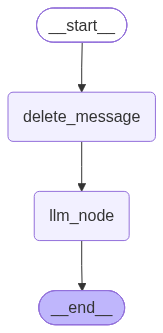

In [12]:
import os
from dotenv import load_dotenv
from langchain.messages import AIMessage, HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import RemoveMessage  

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Define OpenAI Chat Model
llm = ChatOpenAI(model="gpt-5-mini") 

## Define System Message
system_msg = """You are a travel planner assistant. You should always give brief response in one line """

## Define LLM Node
def llm_node(state: MessagesState):
    return {"messages": [llm.invoke([SystemMessage(content=system_msg)]+state["messages"])]}

## Define Delete Message Node
def delete_message(state: MessagesState):
    # Delete all but the 4 most recent messages
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-4]]
    return {"messages": delete_messages}

## Create StateGraph
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("delete_message", delete_message)
graph_builder.add_node("llm_node", llm_node)
graph_builder.add_edge(START, "delete_message")
graph_builder.add_edge("delete_message", "llm_node")
graph_builder.add_edge("llm_node", END)

## Initialize Checkpointer
checkpointer = InMemorySaver()

## Compile graph
graph = graph_builder.compile(checkpointer=checkpointer)

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


In [13]:
## Create list of Messages (Simulates running conversation)
messages = [HumanMessage("Hi.. my name is Ankur", id ="msg-1"),
            AIMessage("Hi! Where would you like to visit?", id ="msg-2"),
            HumanMessage("I like safari", id ="msg-3"),
            AIMessage("Consider the Serengeti in Tanzania for an incredible safari experience.", id ="msg-4"),
            HumanMessage("Do you know my name?", id ="msg-5"),
           ]

## Define Thread Configuration
config = {"configurable": {"thread_id": "s1"}}

## Invoke Graph
response = graph.invoke({"messages": messages}, config=config)

## Print Conversation Messages
for msg in response['messages']:
    msg.pretty_print()


================================== Ai Message ==================================

Hi! Where would you like to visit?
================================ Human Message =================================

I like safari
================================== Ai Message ==================================

Consider the Serengeti in Tanzania for an incredible safari experience.
================================ Human Message =================================

Do you know my name?
================================== Ai Message ==================================

No — I don't know your name; tell me if you'd like me to use it.


### Filter Out Old Messages

#### LangChain Trim Messages Utility

In [14]:
from langchain.messages import AIMessage, HumanMessage, SystemMessage
from langchain_core.messages.utils import trim_messages, count_tokens_approximately 

## Create list of Messages (Simulates running conversation)
messages = [SystemMessage("You are a travel planner assistant. You should always give brief response in one line"),
            HumanMessage("Hi.. my name is Ankur"),
            AIMessage("Hi! Where would you like to visit?"),
            HumanMessage("I like safari"),
            AIMessage("Consider the Serengeti in Tanzania for an incredible safari experience."),
            HumanMessage("Do you know my name?"),
           ]

## Trim Message List
trim_messages(
    messages=messages,
    max_tokens=75,
    strategy="last",
    token_counter=count_tokens_approximately,
    allow_partial=False,
    include_system=True
)


[SystemMessage(content='You are a travel planner assistant. You should always give brief response in one line', additional_kwargs={}, response_metadata={}),
 HumanMessage(content='I like safari', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Consider the Serengeti in Tanzania for an incredible safari experience.', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='Do you know my name?', additional_kwargs={}, response_metadata={})]

### Complete Example Of Trim Message

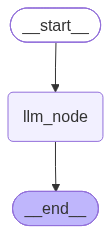

In [15]:
import os
from dotenv import load_dotenv
from langchain.messages import AIMessage, HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages.utils import trim_messages, count_tokens_approximately  

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Define OpenAI Chat Model
llm = ChatOpenAI(model="gpt-5-mini")

## Define llm node function
def llm_node(state: MessagesState):
    trimmed_messages = trim_messages(  
        messages=state["messages"],
        strategy="last",
        token_counter=count_tokens_approximately,
        max_tokens=75,
        allow_partial=False,
        include_system=True
    )
    print("Trimmed Message Sent To LLM:\n")
    print(trimmed_messages)
    return {"messages": [llm.invoke(trimmed_messages)]}


## Create StateGraph
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("llm_node", llm_node)
graph_builder.add_edge(START, "llm_node")
graph_builder.add_edge("llm_node", END)

## Initialize Checkpointer
checkpointer = InMemorySaver()

## Compile graph
graph = graph_builder.compile(checkpointer=checkpointer)

## Visualize Graph (optional)
display(Image(graph.get_graph().draw_mermaid_png()))


In [16]:
## Create list of Messages (Simulates running conversation)
messages = [SystemMessage("You are a travel planner assistant. You should always give brief response in one line"),
            HumanMessage("Hi.. my name is Ankur"),
            AIMessage("Hi! Where would you like to visit?"),
            HumanMessage("I like safari"),
            AIMessage("Consider the Serengeti in Tanzania for an incredible safari experience."),
            HumanMessage("Do you know my name?"),
           ]

## Define Thread Configuration
config = {"configurable": {"thread_id": "L1"}}

## Invoke Graph
response = graph.invoke({"messages": messages}, config)

## Print AI Message
response["messages"][-1].pretty_print()


Trimmed Message Sent To LLM:

[SystemMessage(content='You are a travel planner assistant. You should always give brief response in one line', additional_kwargs={}, response_metadata={}, id='0180a4eb-6b4c-4853-97e3-780ba947042c'), HumanMessage(content='I like safari', additional_kwargs={}, response_metadata={}, id='f9f89717-ca74-4bc8-bad6-85b4a72ceb4f'), AIMessage(content='Consider the Serengeti in Tanzania for an incredible safari experience.', additional_kwargs={}, response_metadata={}, id='31e9bada-3acf-45b7-8655-2953a54fd1bf', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='Do you know my name?', additional_kwargs={}, response_metadata={}, id='e1e97ae0-f6a4-4a6c-b9d2-a94cb2c24181')]
================================== Ai Message ==================================

No — I don't know your name unless you tell me.


In [17]:
## Print Messages
for msg in response['messages']:
    msg.pretty_print()


================================ System Message ================================

You are a travel planner assistant. You should always give brief response in one line
================================ Human Message =================================

Hi.. my name is Ankur
================================== Ai Message ==================================

Hi! Where would you like to visit?
================================ Human Message =================================

I like safari
================================== Ai Message ==================================

Consider the Serengeti in Tanzania for an incredible safari experience.
================================ Human Message =================================

Do you know my name?
================================== Ai Message ==================================

No — I don't know your name unless you tell me.


### Summarize Old Messages

#### Complete Example Of Summarization Node

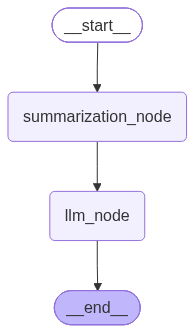

In [20]:
import os
from dotenv import load_dotenv
from typing import Any, TypedDict
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from langchain.chat_models import init_chat_model
from langchain.messages import AnyMessage, HumanMessage, AIMessage, SystemMessage
from langchain_core.messages.utils import count_tokens_approximately
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langmem.short_term import SummarizationNode, RunningSummary  

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Define OpenAI Chat Model
llm = ChatOpenAI(model="gpt-5-mini") 

## Define State Schema
class State(MessagesState):
    context: dict[str, RunningSummary]  
    summarized_messages: list[AnyMessage]

## Initialize Summarization Node
summarization_node = SummarizationNode(  
    token_counter=count_tokens_approximately,
    model=llm,
    max_tokens=200,
    max_tokens_before_summary=20,
    max_summary_tokens=128,
)

## Define LLM Node
def llm_node(state: State):  
    response = llm.invoke(state["summarized_messages"])
    return {"messages": [response]}

## Create StateGraph
graph_builder = StateGraph(State)
graph_builder.add_node(llm_node)
graph_builder.add_node("summarization_node", summarization_node)  
graph_builder.add_edge(START, "summarization_node")
graph_builder.add_edge("summarization_node", "llm_node")
graph = graph_builder.compile(checkpointer=InMemorySaver())

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


In [21]:
## Create list of Messages (Simulates running conversation)
messages = [SystemMessage("You are a travel planner assistant. You should always give brief response in one line"),
            HumanMessage("Hi.. my name is Ankur"),
            AIMessage("Hi! Where would you like to visit?"),
            HumanMessage("I like safari"),
            AIMessage("Consider the Serengeti in Tanzania for an incredible safari experience."),
            HumanMessage("Do you know my name?"),
           ]

## Define Thread Configuration
config = {"configurable": {"thread_id": "s1"}}

## Invoke Graph
response = graph.invoke({"messages": messages}, config=config)

## Print Conversation Messages
for msg in response['messages']:
    msg.pretty_print()


================================ System Message ================================

You are a travel planner assistant. You should always give brief response in one line
================================ Human Message =================================

Hi.. my name is Ankur
================================== Ai Message ==================================

Hi! Where would you like to visit?
================================ Human Message =================================

I like safari
================================== Ai Message ==================================

Consider the Serengeti in Tanzania for an incredible safari experience.
================================ Human Message =================================

Do you know my name?
================================== Ai Message ==================================

Yes — your name is Ankur.


In [22]:
## Print Conversation Messages with Summary
for msg in response['summarized_messages']:
    msg.pretty_print()


================================ System Message ================================

You are a travel planner assistant. You should always give brief response in one line
================================ System Message ================================

Summary of the conversation so far: User introduced himself as Ankur. Assistant greeted him and asked, "Where would you like to visit?"
================================ Human Message =================================

I like safari
================================== Ai Message ==================================

Consider the Serengeti in Tanzania for an incredible safari experience.
================================ Human Message =================================

Do you know my name?


In [23]:
## Print context field
response['context']


{'running_summary': RunningSummary(summary='User introduced himself as Ankur. Assistant greeted him and asked, "Where would you like to visit?"', summarized_message_ids={'0ff7d72f-bdff-4e11-a0a7-3863eb201c1b', '99f5c0e8-17c0-4132-a15c-397b33410275'}, last_summarized_message_id='99f5c0e8-17c0-4132-a15c-397b33410275')}

## <font color="#3366FF">LangGraph Store For Long-Term Memory</font>

### Example Of InMemoryStore

#### Put Method

In [24]:
from langgraph.store.memory import InMemoryStore

## Initialize InMemoryStore
in_memory_store = InMemoryStore()

## Define Namespace for the memory store
user_id = "john@213"
memory_namespace = ("user_profile",user_id)

## Define first memory type as key 
key = "profile"
## Define value of key (should be a dictionary)
value = {"memory" : "John is a young person who lives in London"}

## Save memory to namespace
in_memory_store.put(memory_namespace, key, value)

## Define second memory type as key 
key = "preference"
## Define value of key (should be a dictionary)
value = {"memory" : "John likes beaches and prefers family trips"}

## Save memory to namespace
in_memory_store.put(memory_namespace, key, value)


#### Search Method

In [25]:
## Define Namespace for the memory store
user_id = "john@213"
memory_namespace = ("user_profile",user_id)

## Search Store for details with namespace
memories = in_memory_store.search(memory_namespace)
print(memories)


[Item(namespace=['user_profile', 'john@213'], key='profile', value={'memory': 'John is a young person who lives in London'}, created_at='2026-10-14T20:12:07.863371+00:00', updated_at='2026-10-14T20:12:07.863377+00:00', score=None), Item(namespace=['user_profile', 'john@213'], key='preference', value={'memory': 'John likes beaches and prefers family trips'}, created_at='2026-10-14T20:12:07.865512+00:00', updated_at='2026-10-14T20:12:07.865513+00:00', score=None)]


In [26]:
## Check first data item
print(memories[0].dict())


{'namespace': ['user_profile', 'john@213'], 'key': 'profile', 'value': {'memory': 'John is a young person who lives in London'}, 'created_at': '2026-10-14T20:12:07.863371+00:00', 'updated_at': '2026-10-14T20:12:07.863377+00:00', 'score': None}


#### Get Method

In [27]:
## Define namespace and key
user_id = "john@213"
memory_namespace = ("user_profile",user_id)
key = "preference"

## Get the memory by namespace and key
memory_item = in_memory_store.get(memory_namespace, key)

## Print memory item
print(memory_item.dict())


{'namespace': ['user_profile', 'john@213'], 'key': 'preference', 'value': {'memory': 'John likes beaches and prefers family trips'}, 'created_at': '2026-10-14T20:12:07.865512+00:00', 'updated_at': '2026-10-14T20:12:07.865513+00:00'}


## <font color="#3366FF">Implementing Long-Term Memory</font>

### Example With InMemoryStore

#### Setup

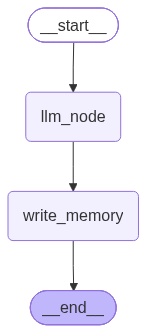

In [1]:
import os
from dotenv import load_dotenv
from langchain_core.runnables import RunnableConfig
from langchain.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.store.base import BaseStore
from langgraph.store.memory import InMemoryStore 

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Define OpenAI Chat Model
llm = ChatOpenAI(model="gpt-5-mini") 

def llm_node(state: MessagesState, config: RunnableConfig, store: BaseStore):

    ## Define System Message
    system_message = """You are a travel planner assistant. You should always give brief response in one line. 
    If you have prior information for this user in your memory, use it to personalize your responses.
    Here is the memory (it may be empty): {memory}"""
    
    ## Fetch user ID from the config
    user_id = config["configurable"]["user_id"]

    ## Get memory from the store using namespace and key
    memory_namespace = ("user_profile",user_id)
    key = "profile"
    existing_memory = store.get(memory_namespace, key)

    ## Retrieve the actual memory content if it exists
    if existing_memory:
        ## Value is a dictionary with a memory key
        existing_memory_content = existing_memory.value.get('memory')
    else:
        existing_memory_content = "No existing memory found."

    ## Format the system prompt with memory content
    system_msg = system_message.format(memory=existing_memory_content)
    
    ## Invoke LLM using memory as well as the chat history
    response = llm.invoke([SystemMessage(content=system_msg)]+state["messages"])

    return {"messages": response}

def write_memory(state: MessagesState, config: RunnableConfig, store: BaseStore):

    ## Create new memory from the chat history and any existing memory
    generate_memory_instruction = """"You have to collect information about the user to personalize future responses.
    
    CURRENT USER INFORMATION:
    {memory}
    
    INSTRUCTIONS:
    1. Review the chat history below carefully
    2. Identify new factual information about the user, such as:
       - Personal details (name, location)
       - Travel Preferences (likes, dislikes)
       - Family/Solo/Couple
       - Past experiences
    3. Merge any new information with existing user information
    4. Structure the memory as a clear, bulleted list
    5. If new information conflicts with existing memory, keep the most recent version
    
    Remember: Only include factual information directly stated by the user. Do not make assumptions or inferences.
    
    Based on the chat history below, please update the user information:"""
    
    ## Fetch user ID from the config
    user_id = config["configurable"]["user_id"]

    ## Get memory from the store using namespace and key
    memory_namespace = ("user_profile",user_id)
    key = "profile"
    existing_memory = store.get(memory_namespace, key)
        
    ## Extract the memory if it exists
    if existing_memory:
        existing_memory_content = existing_memory.value.get('memory')
    else:
        existing_memory_content = "No existing memory found."

    ## Format the memory in the system prompt
    system_msg = generate_memory_instruction.format(memory=existing_memory_content)

    ## Invoke LLM to create new memory
    new_memory = llm.invoke([SystemMessage(content=system_msg)]+state['messages'])

    ## Write new memory as a dictionary with a memory key
    store.put(memory_namespace, key, {"memory": new_memory.content})

## Create the graph
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("llm_node", llm_node)
graph_builder.add_node("write_memory", write_memory)
graph_builder.add_edge(START, "llm_node")
graph_builder.add_edge("llm_node", "write_memory")
graph_builder.add_edge("write_memory", END)

## Initialize Store for long-term (across-thread) memory
store = InMemoryStore()

## Initialize Checkpointer for short-term (within-thread) memory
checkpointer = InMemorySaver()

## Compile the graph with the checkpointer and store
graph = graph_builder.compile(checkpointer=checkpointer, store=store)

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


#### Invoke Graph

In [2]:
## Create config with thread ID for short-term memory & user_id for long-term memory
config = {"configurable": {"thread_id": "s1", "user_id": "john@213"}}

## User's first input 
input_messages = [HumanMessage(content="Hi, my name is John and am interested in beach holiday")]

## Invoke graph with first input & config
response = graph.invoke({"messages": input_messages}, config)

## User's second input 
input_messages = [HumanMessage(content="How far is it from Sydney?")]

## Invoke graph with second input & config
response = graph.invoke({"messages": input_messages}, config)

## Print Conversation Messages
for msg in response['messages']:
    msg.pretty_print()


================================ Human Message =================================

Hi, my name is John and am interested in beach holiday
================================== Ai Message ==================================

Hi John—great, I can help with a beach holiday; do you have preferred dates, budget, destination region, travel companions, and activities (relaxing, watersports, nightlife) so I can suggest options?
================================ Human Message =================================

How far is it from Sydney?
================================== Ai Message ==================================

Which beach or destination do you mean, John—tell me the place and whether you want distance, driving time, or flight time from Sydney?


In [3]:
## Get memory from the store using namespace and key
user_id = "john@213"
memory_namespace = ("user_profile",user_id)
key = "profile"
existing_memory = store.get(memory_namespace, key)
existing_memory.dict()


{'namespace': ['user_profile', 'john@213'],
 'key': 'profile',
 'value': {'memory': '- Name: John\n- Travel interest: beach holiday'},
 'created_at': '2026-10-14T20:20:27.329943+00:00',
 'updated_at': '2026-10-14T20:20:27.329964+00:00'}

#### Invoke Graph With New Thread

In [5]:
## Create config with another thread ID but same user_id
config = {"configurable": {"thread_id": "s2", "user_id": "john@213"}}

## User input 
input_messages = [HumanMessage(content="Please suggest some trip ideas over weekend with family")]

# Invoke graph with config
response = graph.invoke({"messages": input_messages}, config)

## Print Conversation Messages
for msg in response['messages']:
    msg.pretty_print()


================================ Human Message =================================

Please suggest some trip ideas over weekend with family
================================== Ai Message ==================================

John — family-friendly weekend beach trip ideas: beachfront resort with kids’ club & pool; cozy beach cottage for BBQs & sandcastle days; coastal town with aquarium, boardwalk & mini-golf; short ferry island for snorkeling, hikes & picnic; beachfront glamping/camping with bonfire & stargazing.


#### Check Memory In Store

In [6]:
## Get memory from the store using namespace and key
user_id = "john@213"
memory_namespace = ("user_profile",user_id)
key = "profile"
existing_memory = store.get(memory_namespace, key)
existing_memory.dict()


{'namespace': ['user_profile', 'john@213'],
 'key': 'profile',
 'value': {'memory': '- Name: John\n- Travel interest: beach holiday\n- Travel companion: family\n- Trip duration preference: weekend trips'},
 'created_at': '2026-10-14T20:22:01.640637+00:00',
 'updated_at': '2026-10-14T20:22:01.640662+00:00'}

### Example With PostgresStore

#### Set Up In Postgres DB

##### Important: Change DB_URI according to your Postgres setup first

In [7]:
import psycopg
from langgraph.store.postgres import PostgresStore  

## Define Postgres connection string
DB_URI = "postgresql://ankur@localhost/postgres?options=-c%20search_path%3Dlanggraph"

## Create "langgraph" schema in database
with psycopg.connect(DB_URI, autocommit=True) as conn:
    with conn.cursor() as cur:
        cur.execute("CREATE SCHEMA IF NOT EXISTS langgraph")

## Create Tables for PostgresStore
with PostgresStore.from_conn_string(DB_URI) as store:
    store.setup()


#### Example Of PostgresStore

In [8]:
import os
import psycopg
from dotenv import load_dotenv
from langchain_core.runnables import RunnableConfig
from langchain.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.checkpoint.postgres import PostgresSaver
from langgraph.store.base import BaseStore
from langgraph.store.postgres import PostgresStore  


## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Define OpenAI Chat Model
llm = ChatOpenAI(model="gpt-5-mini") 

## Define Postgres connection string
DB_URI = "postgresql://ankur@localhost/postgres?options=-c%20search_path%3Dlanggraph"


## <code for llm_node() same as earlier example>

## <code for write_memory() same as earlier example>

## <code for StateGraph creation, same as earlier example>


with (
    PostgresStore.from_conn_string(DB_URI) as store,  
    PostgresSaver.from_conn_string(DB_URI) as checkpointer,
):
        
        ## Compile the graph with the checkpointer and store
        graph = graph_builder.compile(checkpointer=checkpointer, store=store)

        ## Create config with thread ID for short-term memory & user_id for long-term memory
        config = {"configurable": {"thread_id": "s1", "user_id": "john@213"}}

        ## User input 
        input_messages = [HumanMessage(content="Hi, my name is John and am interested in beach holiday")]
        
        # Invoke graph with config
        response = graph.invoke({"messages": input_messages}, config)
        
        ## Print Conversation Messages
        for msg in response['messages']:
            msg.pretty_print()


================================ Human Message =================================

Hi, my name is John and am interested in beach holiday
================================== Ai Message ==================================

Hi John! How about a beach holiday in the Maldives or Hawaii?
================================ Human Message =================================

Hi, my name is John and am interested in beach holiday
================================== Ai Message ==================================

Hi John — since you love beach holidays, would you prefer relaxing luxury (Maldives), surf and culture (Bali), volcanic beaches and hikes (Hawaii), or Caribbean all‑inclusive resorts?


In [9]:
## Define Postgres connection string
DB_URI = "postgresql://ankur@localhost/postgres?options=-c%20search_path%3Dlanggraph"

with (
    PostgresStore.from_conn_string(DB_URI) as store,  
    PostgresSaver.from_conn_string(DB_URI) as checkpointer,
):

        ## Get memory from the store using namespace and key
        user_id = "john@213"
        memory_namespace = ("user_profile",user_id)
        key = "profile"
        existing_memory = store.get(memory_namespace, key)
        print(existing_memory.dict())


{'namespace': ['user_profile', 'john@213'], 'key': 'profile', 'value': {'memory': '- Name: John\n- Interests: Beach holiday'}, 'created_at': '2025-12-31T00:08:20.729286+05:30', 'updated_at': '2026-10-15T01:55:22.425923+05:30'}
